# Phase 2: EDA, ABC/XYZ Segmentation and Lead Time Bottlenecks

**Project:** FMCG Global Demand Planning Capstone
**Input:** `data/fmcg_clean.csv` (produced in Phase 1)
**Output:** `data/abc_xyz_segments.csv` (one row per store-SKU series, used in later phases)

## Objectives
1. Explore demand patterns over time, geography, channel and category.
2. **ABC analysis:** which series drive most of the revenue (value importance).
3. **XYZ analysis:** which series have stable vs erratic demand (forecastability).
4. Combine them into a **3x3 ABC/XYZ matrix** to guide planning effort.
5. Identify **lead time bottlenecks** (slow or unreliable suppliers) and link them to stock-outs.

**Unit of analysis:** a *series* is one SKU in one store (`store_id` + `sku_id`). This is the level we will forecast in Phases 4-5.

## 1. Setup and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 4)

# parse_dates converts the 'date' column from text to real datetimes,
# which lets us resample and group by week/month later.
df = pd.read_csv("../data/fmcg_clean.csv", parse_dates=["date"])

# A series = one SKU in one store. We build a single key for it.
df["series_id"] = df["store_id"] + "_" + df["sku_id"]

In [2]:
# Sanity checks: these should match the Phase 1 summary.
print("Rows:", f"{len(df):,}")
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Countries:", df["country"].nunique(), "| Cities:", df["city"].nunique(),
      "| Stores:", df["store_id"].nunique(), "| SKUs:", df["sku_id"].nunique(),
      "| Suppliers:", df["supplier_id"].nunique())
print("Store-SKU series:", df["series_id"].nunique())

Rows: 1,100,000
Date range: 2021-01-01 to 2023-12-31
Countries: 7 | Cities: 9 | Stores: 13 | SKUs: 102 | Suppliers: 60
Store-SKU series: 1005


## 2. Exploratory Data Analysis

### 2.1 Demand over time
We aggregate to total daily units across everything, then add a 30-day rolling mean. The rolling mean smooths daily noise so the long-term trend and seasonality are visible.

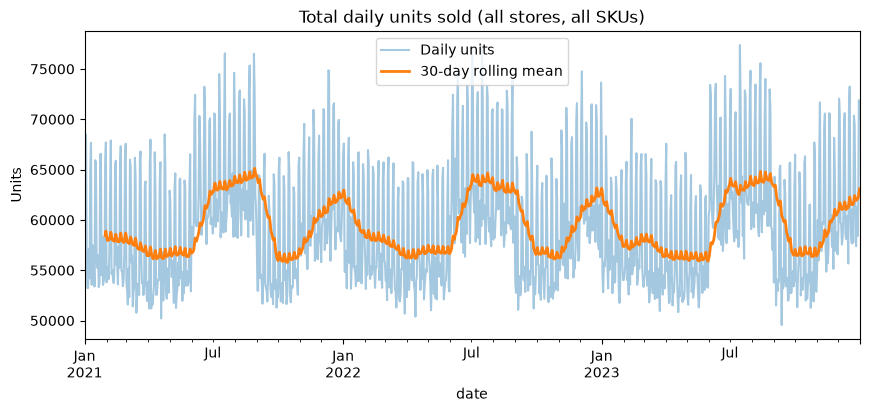

In [3]:
daily = df.groupby("date")["units_sold"].sum()

ax = daily.plot(alpha=0.4, label="Daily units")
daily.rolling(30).mean().plot(ax=ax, linewidth=2, label="30-day rolling mean")
ax.set_title("Total daily units sold (all stores, all SKUs)")
ax.set_ylabel("Units")
ax.legend()
plt.show()

### 2.2 Monthly revenue and seasonality

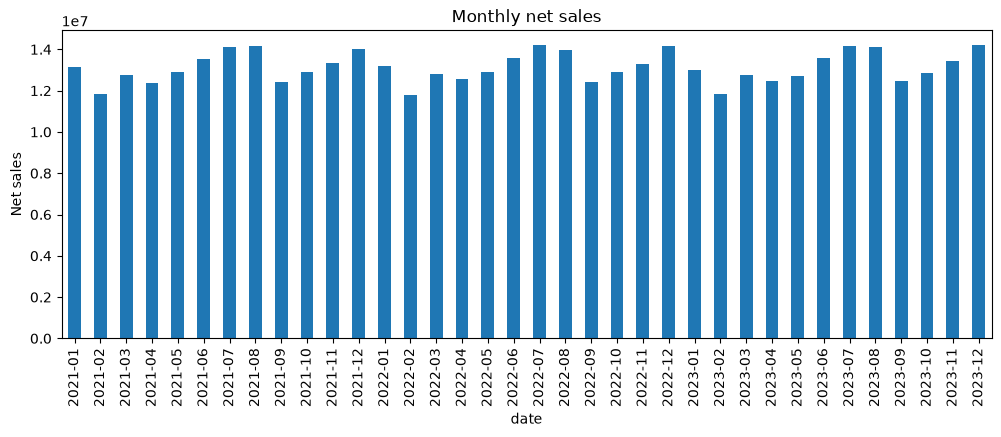

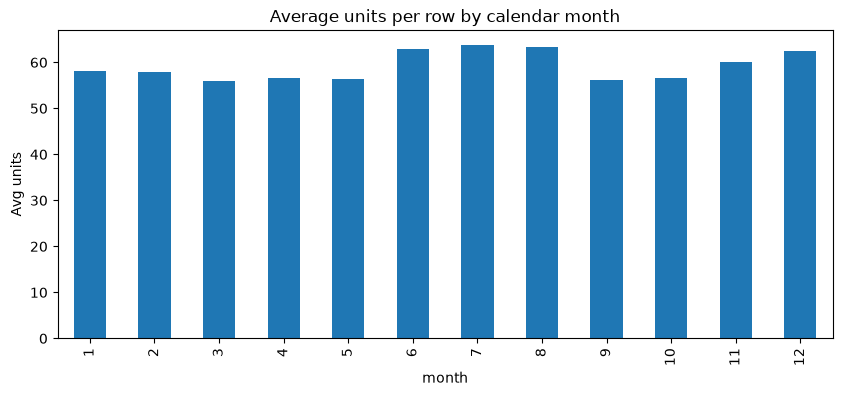

In [4]:
monthly = df.groupby(df["date"].dt.to_period("M"))["net_sales"].sum()
monthly.plot(kind="bar", figsize=(12, 4), title="Monthly net sales")
plt.ylabel("Net sales")
plt.show()

# Average units per month-of-year across all years: reveals repeating seasonal shape.
season = df.groupby("month")["units_sold"].mean()
season.plot(kind="bar", title="Average units per row by calendar month")
plt.ylabel("Avg units")
plt.show()

### 2.3 Weekday pattern, holidays and promotions
Here `weekday` is 0 = Monday ... 6 = Sunday (the first row, 2021-01-01, is a Friday and shows 4).

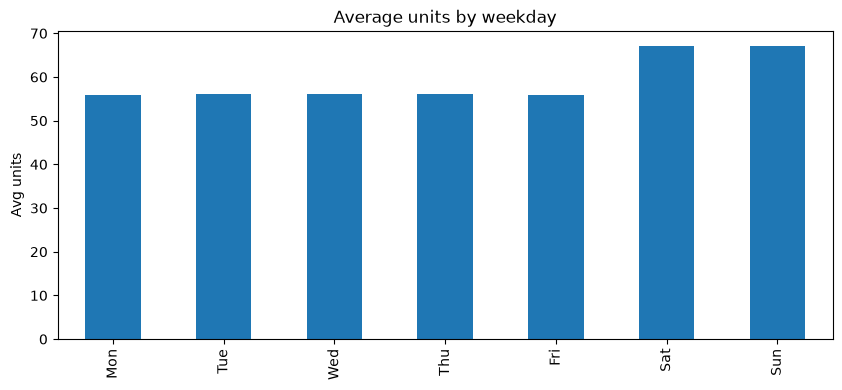

Average units, holiday vs non-holiday:
is_holiday
0   59.15
1   62.74
Name: units_sold, dtype: float64

Average units, promo vs no promo (raw difference, tested formally in Phase 3):
promo_flag
0    55.26
1   104.27
Name: units_sold, dtype: float64


In [5]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = df.groupby("weekday")["units_sold"].mean()
wd.index = weekday_names
wd.plot(kind="bar", title="Average units by weekday")
plt.ylabel("Avg units")
plt.show()

print("Average units, holiday vs non-holiday:")
print(df.groupby("is_holiday")["units_sold"].mean())
print("\nAverage units, promo vs no promo (raw difference, tested formally in Phase 3):")
print(df.groupby("promo_flag")["units_sold"].mean())

### 2.4 Where does the revenue come from? (country, channel, category)

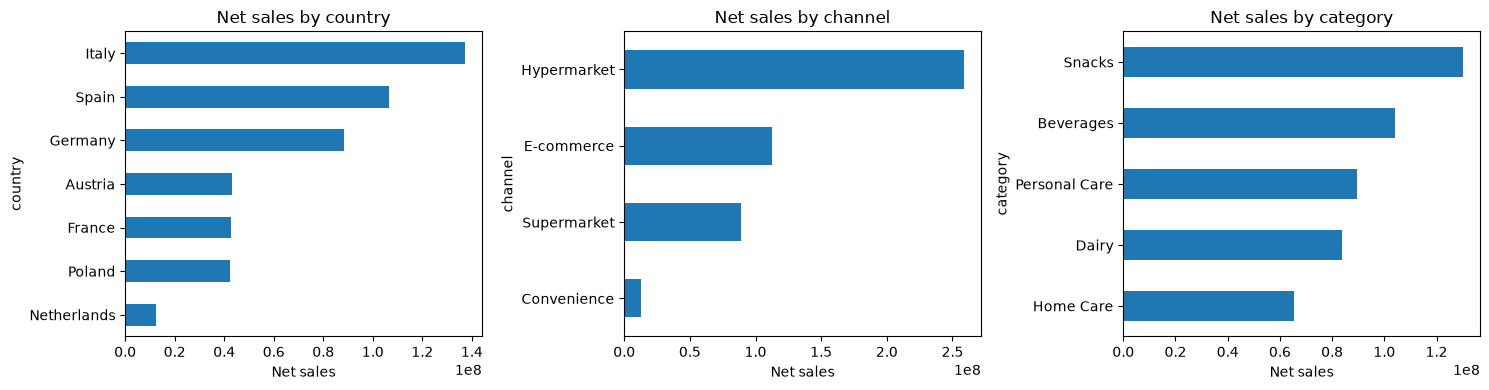

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["country", "channel", "category"]):
    df.groupby(col)["net_sales"].sum().sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Net sales by {col}")
    ax.set_xlabel("Net sales")
plt.tight_layout()
plt.show()

In [22]:
# Numeric summary of section 2, so we can read the effects, not just eyeball plots.

# Yearly totals: is demand growing?
print("Net sales by year:")
print(df.groupby("year")["net_sales"].sum())

# Seasonality: average daily units per calendar month, relative to the overall mean.
m = df.groupby("month")["units_sold"].mean()
print("\nMonthly index (1.00 = average):")
print((m / m.mean()).round(3))

# Weekday index (0 = Monday).
w = df.groupby("weekday")["units_sold"].mean()
print("\nWeekday index (1.00 = average):")
print((w / w.mean()).round(3))

# Promo, holiday and weekend effects on average units.
for col in ["promo_flag", "is_holiday", "is_weekend"]:
    print(f"\nAverage units by {col}:")
    print(df.groupby(col)["units_sold"].mean().round(2))

# Discount depth vs units, for promo rows only.
print("\nAverage units by discount_pct (promo rows only):")
print(df[df["promo_flag"] == 1].groupby("discount_pct")["units_sold"].mean().round(2))

# Share of net sales by country, channel and category.
for col in ["country", "channel", "category"]:
    print(f"\nNet sales share by {col} (%):")
    print((df.groupby(col)["net_sales"].sum() / df["net_sales"].sum() * 100).round(1))

Net sales by year:
year
2021   157,560,186.14
2022   157,816,191.60
2023   157,570,075.09
Name: net_sales, dtype: float64

Monthly index (1.00 = average):
month
1    0.98
2    0.98
3    0.95
4    0.96
5    0.95
6    1.06
7    1.08
8    1.07
9    0.95
10   0.96
11   1.02
12   1.05
Name: units_sold, dtype: float64

Weekday index (1.00 = average):
weekday
0   0.94
1   0.95
2   0.95
3   0.95
4   0.94
5   1.13
6   1.14
Name: units_sold, dtype: float64

Average units by promo_flag:
promo_flag
0    55.26
1   104.27
Name: units_sold, dtype: float64

Average units by is_holiday:
is_holiday
0   59.15
1   62.74
Name: units_sold, dtype: float64

Average units by is_weekend:
is_weekend
0   56.02
1   67.10
Name: units_sold, dtype: float64

Average units by discount_pct (promo rows only):
discount_pct
0.10    94.33
0.15   100.30
0.20   106.70
0.30   116.18
Name: units_sold, dtype: float64

Net sales share by country (%):
country
Austria        9.10
France         9.00
Germany       18.70
Italy       

## 3. ABC Analysis (value importance)

**Idea (Pareto principle):** a small share of series generates most of the revenue.
- **A:** series making up the first 80% of cumulative net sales
- **B:** the next 15% (80-95%)
- **C:** the remaining 5%

Steps: total net sales per series, sort high to low, compute each series' share and the running (cumulative) share, then assign classes. We use the cumulative share *before* adding the current series, so the series that crosses the 80% line still counts as A.

In [7]:
abc = (df.groupby("series_id")["net_sales"].sum()
         .sort_values(ascending=False)
         .to_frame("net_sales"))

abc["share"] = abc["net_sales"] / abc["net_sales"].sum()
abc["cum_share"] = abc["share"].cumsum()
cum_before = abc["cum_share"] - abc["share"]

abc["abc_class"] = np.select(
    [cum_before < 0.80, cum_before < 0.95],
    ["A", "B"],
    default="C",
)

print(abc["abc_class"].value_counts().sort_index())
print("\nShare of revenue by class:")
print(abc.groupby("abc_class")["share"].sum())

abc_class
A    480
B    285
C    240
Name: count, dtype: int64

Share of revenue by class:
abc_class
A   0.80
B   0.15
C   0.05
Name: share, dtype: float64


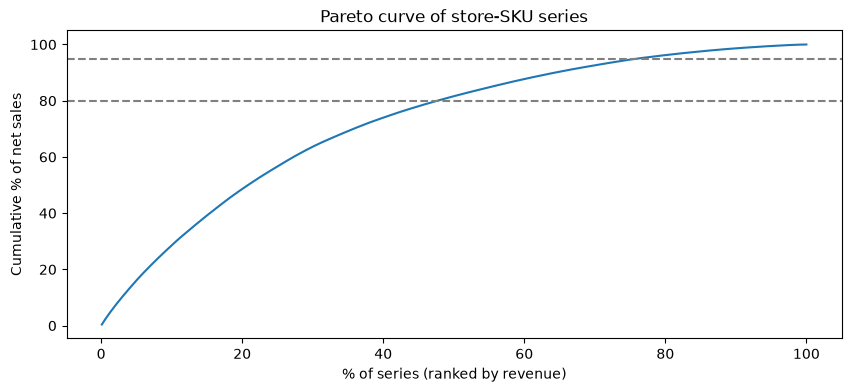

In [8]:
# Pareto curve: how quickly does cumulative revenue build up?
x = np.arange(1, len(abc) + 1) / len(abc) * 100
plt.plot(x, abc["cum_share"].values * 100)
plt.axhline(80, linestyle="--", color="grey")
plt.axhline(95, linestyle="--", color="grey")
plt.xlabel("% of series (ranked by revenue)")
plt.ylabel("Cumulative % of net sales")
plt.title("Pareto curve of store-SKU series")
plt.show()

## 4. XYZ Analysis (demand variability)

**Idea:** measure how erratic each series' demand is using the **coefficient of variation (CV)**:

$$CV = \frac{\text{standard deviation}}{\text{mean}}$$

A low CV means demand is steady and easy to forecast; a high CV means it swings a lot.
- **X:** CV < 0.5 (stable)
- **Y:** 0.5 <= CV < 1.0 (moderate)
- **Z:** CV >= 1.0 (erratic)

**Why weekly, not daily?** Daily store-level demand is noisy and contains zero days, which inflates CV for almost everyone. Weekly totals give a fairer view of underlying variability. The first and last weeks of the data may be partial; with 3 years of data this has a negligible effect.

These cut-offs (0.5 / 1.0) are common conventions, not laws. We will check sensitivity below.

In [9]:
weekly = (df.groupby(["series_id", pd.Grouper(key="date", freq="W")])["units_sold"]
            .sum()
            .reset_index())

stats = weekly.groupby("series_id")["units_sold"].agg(weekly_mean="mean", weekly_std="std")
stats["cv"] = stats["weekly_std"] / stats["weekly_mean"].replace(0, np.nan)

stats["xyz_class"] = np.select(
    [stats["cv"] < 0.5, stats["cv"] < 1.0],
    ["X", "Y"],
    default="Z",
)

print(stats["cv"].describe())
print()
print(stats["xyz_class"].value_counts().sort_index())

count   1,005.00
mean        0.19
std         0.05
min         0.11
25%         0.14
50%         0.18
75%         0.23
max         0.32
Name: cv, dtype: float64

xyz_class
X    1005
Name: count, dtype: int64


In [23]:
# Do the three CV humps line up with a business attribute?
attrs = df.drop_duplicates("series_id").set_index("series_id")[["category", "channel", "country"]]
cv_attrs = stats[["cv"]].join(attrs)
for col in ["category", "channel", "country"]:
    print(f"\nMean weekly CV by {col}:")
    print(cv_attrs.groupby(col)["cv"].agg(["mean", "min", "max", "count"]).round(3))


Mean weekly CV by category:
               mean  min  max  count
category                            
Beverages      0.25 0.21 0.30    243
Dairy          0.15 0.12 0.20    179
Home Care      0.15 0.12 0.20    162
Personal Care  0.15 0.12 0.21    182
Snacks         0.21 0.15 0.32    239

Mean weekly CV by channel:
             mean  min  max  count
channel                           
Convenience  0.20 0.12 0.32     45
E-commerce   0.19 0.12 0.32    240
Hypermarket  0.19 0.12 0.31    480
Supermarket  0.19 0.12 0.31    240

Mean weekly CV by country:
             mean  min  max  count
country                           
Austria      0.19 0.12 0.29     80
France       0.19 0.12 0.30     80
Germany      0.19 0.12 0.30    160
Italy        0.19 0.12 0.32    320
Netherlands  0.20 0.12 0.32     45
Poland       0.19 0.12 0.31     80
Spain        0.19 0.12 0.32    240


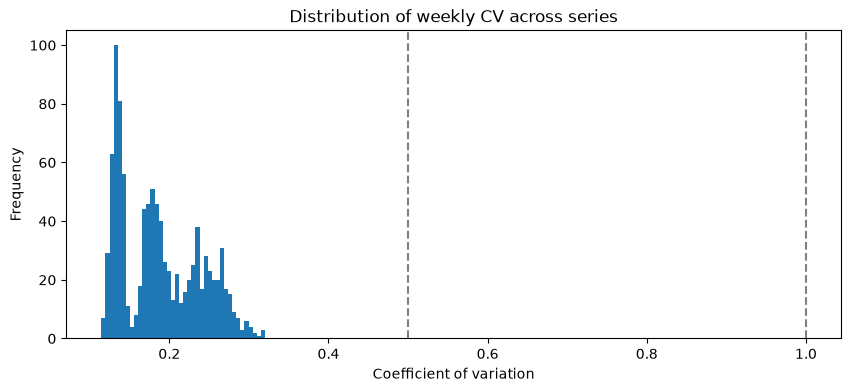

In [10]:
stats["cv"].plot(kind="hist", bins=40, title="Distribution of weekly CV across series")
plt.axvline(0.5, color="grey", linestyle="--")
plt.axvline(1.0, color="grey", linestyle="--")
plt.xlabel("Coefficient of variation")
plt.show()

In [24]:
# Is Beverages' higher CV driven by stronger seasonality?
cat_month = df.groupby(["category", "month"])["units_sold"].mean().unstack(0)
print("Monthly index by category (1.00 = category average):")
print((cat_month / cat_month.mean()).round(2))

Monthly index by category (1.00 = category average):
category  Beverages  Dairy  Home Care  Personal Care  Snacks
month                                                       
1              0.90   1.01       1.01           0.99    1.04
2              0.90   0.99       1.00           0.99    1.03
3              0.89   1.00       0.99           1.00    0.92
4              0.89   1.01       1.00           1.00    0.94
5              0.90   1.00       0.99           0.99    0.93
6              1.31   0.99       1.00           1.00    0.92
7              1.34   1.01       1.00           0.99    0.93
8              1.33   1.00       1.00           1.01    0.92
9              0.89   1.00       1.00           1.00    0.93
10             0.89   1.01       1.00           1.01    0.93
11             0.88   0.99       1.00           1.01    1.19
12             0.89   1.00       1.00           1.01    1.33


## 5. Combined ABC/XYZ matrix
Merge the two classifications. Each series gets a two-letter segment such as **AX** (high value, stable) or **CZ** (low value, erratic).

In [11]:
seg = abc.join(stats[["weekly_mean", "weekly_std", "cv", "xyz_class"]])
seg["segment"] = seg["abc_class"] + seg["xyz_class"]

counts = pd.crosstab(seg["abc_class"], seg["xyz_class"], margins=True)
print("Number of series per segment:")
print(counts)

rev = (seg.pivot_table(index="abc_class", columns="xyz_class",
                       values="share", aggfunc="sum", fill_value=0) * 100)
print("\nShare of total net sales per segment (%):")
print(rev.round(1))

Number of series per segment:
xyz_class     X   All
abc_class            
A           480   480
B           285   285
C           240   240
All        1005  1005

Share of total net sales per segment (%):
xyz_class     X
abc_class      
A         80.10
B         15.00
C          5.00


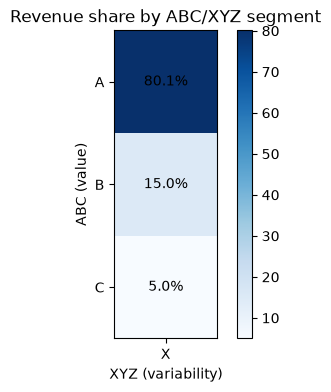

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(rev.values, cmap="Blues")
ax.set_xticks(range(len(rev.columns)), rev.columns)
ax.set_yticks(range(len(rev.index)), rev.index)
for i in range(rev.shape[0]):
    for j in range(rev.shape[1]):
        ax.text(j, i, f"{rev.values[i, j]:.1f}%", ha="center", va="center")
ax.set_title("Revenue share by ABC/XYZ segment")
ax.set_xlabel("XYZ (variability)")
ax.set_ylabel("ABC (value)")
plt.colorbar(im)
plt.show()

### Sensitivity check
If a small change in the CV cut-offs reshuffles many series, our segmentation is fragile. We test two alternative threshold pairs.

In [13]:
for lo, hi in [(0.5, 1.0), (0.4, 0.8), (0.6, 1.2)]:
    cls = np.select([stats["cv"] < lo, stats["cv"] < hi], ["X", "Y"], default="Z")
    print(f"Thresholds {lo}/{hi}:", pd.Series(cls).value_counts().sort_index().to_dict())

Thresholds 0.5/1.0: {'X': 1005}
Thresholds 0.4/0.8: {'X': 1005}
Thresholds 0.6/1.2: {'X': 1005}


## 6. Lead time bottlenecks and stock-outs

Lead time is the days between ordering and receiving stock. Long or unpredictable lead times force higher safety stock and raise stock-out risk.

Note: in this dataset `supplier_id` and `lead_time_days` vary by row (the same SKU in the same store can show different suppliers on different days), so we analyse suppliers across all rows rather than per SKU.

### 6.1 Supplier performance
We look at average lead time, variability (std), the 90th percentile (a "bad day" lead time), and the stock-out rate.

In [14]:
supplier = df.groupby("supplier_id").agg(
    rows=("lead_time_days", "size"),
    mean_lt=("lead_time_days", "mean"),
    std_lt=("lead_time_days", "std"),
    p90_lt=("lead_time_days", lambda s: s.quantile(0.9)),
    stockout_rate=("stock_out_flag", "mean"),
    net_sales=("net_sales", "sum"),
).sort_values("mean_lt", ascending=False)

print("Slowest 10 suppliers by average lead time:")
print(supplier.head(10))
print("\nMost variable 10 suppliers (std of lead time):")
print(supplier.sort_values("std_lt", ascending=False).head(10))

Slowest 10 suppliers by average lead time:
              rows  mean_lt  std_lt  p90_lt  stockout_rate    net_sales
supplier_id                                                            
S036         18239     6.55    2.00    9.00           0.03 7,841,348.16
S015         18280     6.53    2.01    9.00           0.03 7,900,016.05
S048         18315     6.53    2.03    9.00           0.03 7,898,507.73
S019         18502     6.52    2.02    9.00           0.03 7,967,360.89
S025         18300     6.52    1.99    9.00           0.03 7,877,112.65
S059         18394     6.52    2.01    9.00           0.03 7,909,433.26
S030         18227     6.52    2.02    9.00           0.03 7,864,925.27
S056         18344     6.52    2.03    9.00           0.03 7,838,322.56
S022         18240     6.52    2.02    9.00           0.03 7,748,511.32
S054         18198     6.52    2.00    9.00           0.03 7,782,743.80

Most variable 10 suppliers (std of lead time):
              rows  mean_lt  std_lt  p90_lt  

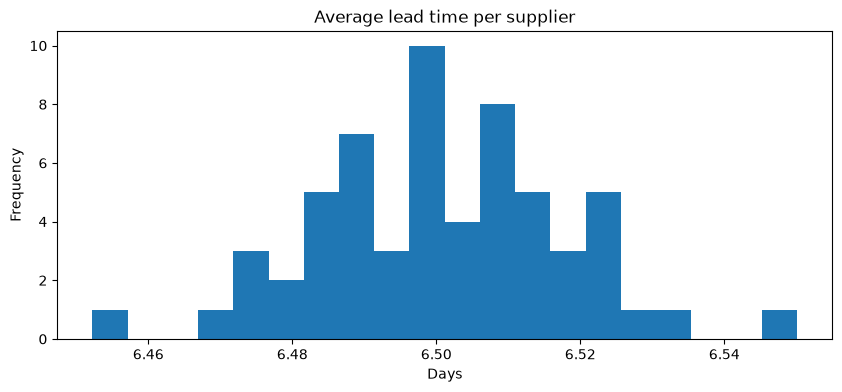

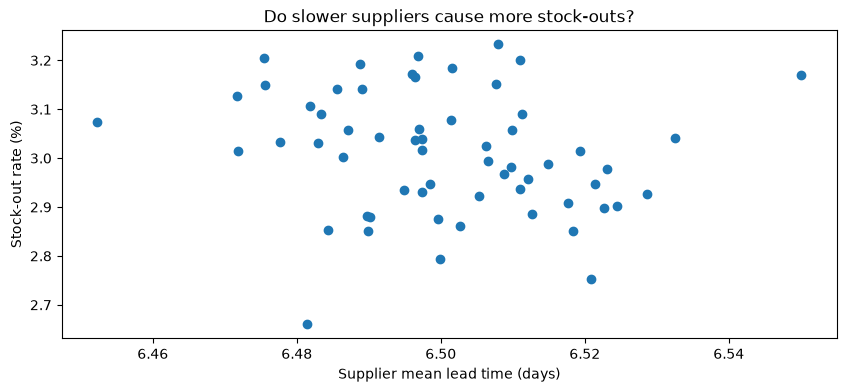

In [15]:
supplier["mean_lt"].plot(kind="hist", bins=20, title="Average lead time per supplier")
plt.xlabel("Days")
plt.show()

plt.scatter(supplier["mean_lt"], supplier["stockout_rate"] * 100)
plt.xlabel("Supplier mean lead time (days)")
plt.ylabel("Stock-out rate (%)")
plt.title("Do slower suppliers cause more stock-outs?")
plt.show()

### 6.2 Lead time by country and category

In [16]:
for col in ["country", "category"]:
    print(f"\nLead time by {col}:")
    print(df.groupby(col)["lead_time_days"].agg(["mean", "std", "max"]).sort_values("mean", ascending=False))


Lead time by country:
             mean  std  max
country                    
Netherlands  6.51 2.03   15
Poland       6.51 2.02   15
Germany      6.51 2.01   15
Spain        6.50 2.02   17
France       6.50 2.02   16
Italy        6.50 2.01   16
Austria      6.49 2.01   15

Lead time by category:
               mean  std  max
category                     
Personal Care  6.50 2.02   16
Beverages      6.50 2.01   15
Home Care      6.50 2.01   17
Snacks         6.50 2.01   16
Dairy          6.50 2.01   15


### 6.3 Does a longer lead time mean more stock-outs?
We bucket lead times and compare stock-out rates, which is easier to read than a raw scatter on 1.1M rows.

           stockout_rate_%    rows
lt_bucket                         
(0, 5]                2.99  339239
(5, 10]               3.02  735808
(10, 15]              3.03   24949
(15, 20]              0.00       4


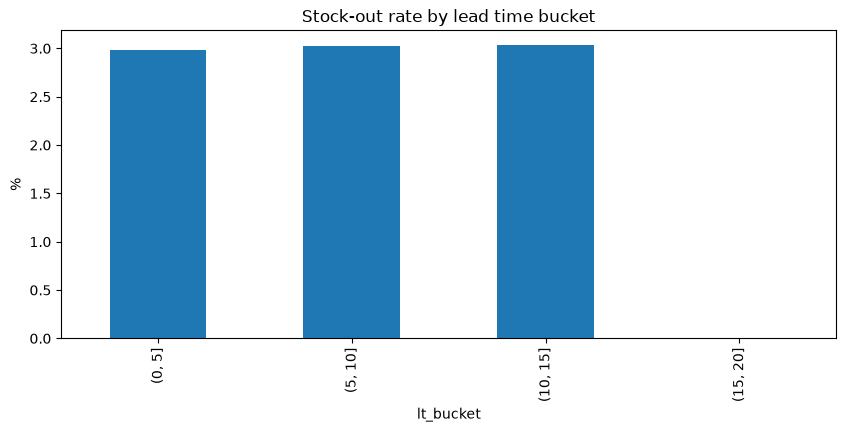

In [17]:
df["lt_bucket"] = pd.cut(df["lead_time_days"], bins=[0, 5, 10, 15, 20, 100])
by_bucket = df.groupby("lt_bucket", observed=True)["stock_out_flag"].agg(["mean", "size"])
by_bucket["mean"] = by_bucket["mean"] * 100
by_bucket.columns = ["stockout_rate_%", "rows"]
print(by_bucket)

by_bucket["stockout_rate_%"].plot(kind="bar", title="Stock-out rate by lead time bucket")
plt.ylabel("%")
plt.show()

### 6.4 Stock-outs inside the most valuable segments
A stock-out on an **A** series costs far more than on a **C** series. We attach each series' segment to the raw rows to check.

In [18]:
df = df.merge(seg[["abc_class", "xyz_class", "segment"]],
              left_on="series_id", right_index=True, how="left")

so = df.groupby("abc_class")["stock_out_flag"].mean() * 100
print("Stock-out rate (%) by ABC class:")
print(so.round(2))

lost = df[df["stock_out_flag"] == 1].groupby("abc_class").size()
print("\nStock-out rows by ABC class:")
print(lost)

Stock-out rate (%) by ABC class:
abc_class
A   2.98
B   3.08
C   2.99
Name: stock_out_flag, dtype: float64

Stock-out rows by ABC class:
abc_class
A    15658
B     9619
C     7837
dtype: int64


In [20]:
# Relative XYZ: split series into three equal-sized groups by CV rank.
# X = most stable third, Z = most variable third (relative to each other).
stats["xyz_rel"] = pd.qcut(stats["cv"], q=3, labels=["X", "Y", "Z"])
print(stats.groupby("xyz_rel", observed=True)["cv"].agg(["min", "max", "count"]))

seg["xyz_rel"] = stats["xyz_rel"]
seg["segment_rel"] = seg["abc_class"] + seg["xyz_rel"].astype(str)
print(pd.crosstab(seg["abc_class"], seg["xyz_rel"], margins=True))

         min  max  count
xyz_rel                 
X       0.11 0.15    335
Y       0.15 0.21    335
Z       0.21 0.32    335
xyz_rel      X    Y    Z   All
abc_class                     
A          184  139  157   480
B           75   88  122   285
C           76  108   56   240
All        335  335  335  1005


## 7. Save segments for later phases

In [21]:
out = seg.reset_index()
out.to_csv("../data/abc_xyz_segments.csv", index=False)
print("Saved", out.shape, "-> data/abc_xyz_segments.csv")
out.head()

Saved (1005, 12) -> data/abc_xyz_segments.csv


,series_id,net_sales,share,cum_share,abc_class,weekly_mean,weekly_std,cv,xyz_class,segment,xyz_rel,segment_rel
0,STORE0008_SKU0027,"1,881,904.66",0.00,0.00,A,899.46,169.79,0.19,X,AX,Y,AY
1,STORE0005_SKU0027,"1,861,905.08",0.00,0.01,A,890.77,178.46,0.20,X,AX,Y,AY
2,STORE0011_SKU0027,"1,857,122.39",0.00,0.01,A,888.50,171.74,0.19,X,AX,Y,AY
3,STORE0004_SKU0027,"1,844,042.20",0.00,0.02,A,878.92,176.11,0.20,X,AX,Y,AY
4,STORE0001_SKU0027,"1,830,340.01",0.00,0.02,A,874.66,175.26,0.20,X,AX,Y,AY


## 8. Summary of findings

**Demand patterns (EDA)**
- **No trend:** annual net sales are flat (157.6M in 2021, 157.8M in 2022, 157.6M in 2023).
  - **Yearly seasonality is category-specific:** Beverages peak in June-August (index 1.31-1.34 vs about 0.89 otherwise) and Snacks peak in November-December (1.19-1.33). Dairy, Home Care and Personal Care show no seasonality (index 0.99-1.01). The aggregate summer and December peaks come from these two categories.
- **Weekly cycle:** Saturday and Sunday run about 13-14% above average (index 1.13-1.14); weekdays sit at 0.94-0.95
- **Holidays:** a small effect (62.7 vs 59.1 average units, about +6%).
- **Promotions (raw association, to be tested in Phase 3):** promo rows average 104.3 units vs 55.3 without (about +89%). Deeper discounts help with diminishing returns (10% off: 94 units; 30% off: 116 units).
- **Concentration:** Italy, Spain and Germany carry about 70% of net sales; hypermarkets 54.7% and e-commerce 23.8%; Snacks (27.5%) and Beverages (22.0%) lead categories.

**ABC analysis (value)**
- 480 of 1,005 series (48%) are needed to reach 80% of revenue, so revenue is spread much more evenly than the typical 80/20 Pareto pattern.

**XYZ analysis (variability)**
- Weekly CV ranges only from 0.11 to 0.32 (mean 0.19), so **all 1,005 series are "X" (stable)** under the standard 0.5 / 1.0 thresholds.
- The CV histogram shows three clusters. **Category explains most of this, through seasonality:** Beverages (mean CV 0.25) and Snacks (0.21) have strong seasonal cycles, while Dairy, Home Care and Personal Care (about 0.15) are flat. Channel and country show no difference (mean CV 0.19-0.20 everywhere).
- A **relative** split into thirds by CV rank is therefore used for prioritisation (X: 0.11-0.15, Y: 0.15-0.21, Z: 0.21-0.32). The differences are small in absolute terms.
- Variability is not clearly linked to revenue class.

**Lead time and stock-outs**
- Supplier lead times are nearly identical (mean 6.45-6.55 days, std about 2 days, 90th percentile 9 days for all suppliers). **No supplier bottleneck was found.**
- Stock-out rate is about 3% everywhere and does not rise with lead time (2.99% / 3.02% / 3.03% across the main lead time buckets) or differ by ABC class (A 2.98%, B 3.08%, C 2.99%).
- Suppliers and lead times vary by row, even for the same store-SKU on consecutive days, which suggests they were assigned at random in this dataset.

**Implications for Phases 3-5**
- Model features: `promo_flag`, `discount_pct`, weekday/weekend, month; `is_holiday` is a weak signal. No trend term is needed.
  - Seasonality must be modelled **per category** (month x category interaction, or separate models per category), alongside the 7-day weekly cycle. A single global month effect would misfit about half the series.
- Stock-out rows (about 3%) understate true demand and should be handled explicitly.
- The promo effect is confounded with timing and series volume, so Phase 3 tests it within series, controlling for weekday and month.
 - Category should be a model feature or a grouping for model selection, since it is the only attribute that separates demand variability.